# NetSentinel: Network Anomaly Detection

**Deep Learning PBL | UNSW-NB15 | Autoencoder**

This notebook learns a representation of benign network flows. At detection time, flows that the model reconstructs poorly are flagged for review. An anomaly is a signal for investigation, not proof of an attack.

## Run it in Google Colab

1. Open [Google Colab](https://colab.research.google.com/), choose **File → Upload notebook**, and upload this `.ipynb` file.
2. Save a copy in your Google Drive. Colab stores the notebook there; the runtime and downloaded CSVs live in temporary cloud storage, so they do not fill your PC.
3. Run the cells from top to bottom. GPU is optional for this small tabular autoencoder; CPU is fine for the first run.

The notebook downloads only the pre-split training and testing CSV files (about tens of MB each) into the temporary Colab runtime. The original dataset page describes these two partitions and the larger raw dataset; we do not need the raw packet captures here. The CSVs below are fetched from a public mirror; cite UNSW-NB15 in your report and use its official page for dataset details.

**Learning path:** setup → download and inspect → clean and encode → train on benign flows → select a threshold using benign validation data → evaluate on the held-out test set.


## 1. Project setup

Use the libraries already available in Colab. We set seeds to make comparisons more repeatable.

In [1]:
import os
import random
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Download the UNSW-NB15 train and test CSVs

These are the compact pre-split feature tables, not the 100 GB packet capture data. They should include a binary `label` (0 = normal, 1 = attack) and `attack_cat`. The notebook checks the schema before continuing.

In [2]:
DATA_DIR = "/content/netsentinel_data"
os.makedirs(DATA_DIR, exist_ok=True)

FILES = {
    "train": "UNSW_NB15_training-set.csv",
    "test": "UNSW_NB15_testing-set.csv",
}
BASE_URL = "https://raw.githubusercontent.com/Nir-J/ML-Projects/master/UNSW-Network_Packet_Classification/"

for filename in FILES.values():
    path = os.path.join(DATA_DIR, filename)
    if not os.path.exists(path):
        url = BASE_URL + filename
        print("Downloading", filename)
        urllib.request.urlretrieve(url, path)

train_df = pd.read_csv(os.path.join(DATA_DIR, FILES["train"]))
test_df = pd.read_csv(os.path.join(DATA_DIR, FILES["test"]))

print("Train shape:", train_df.shape)
print("Test shape: ", test_df.shape)
print("Train columns:", train_df.columns.tolist())
assert {"label", "attack_cat"}.issubset(train_df.columns), "Expected label/attack_cat columns; inspect the downloaded file source."
assert {"label", "attack_cat"}.issubset(test_df.columns), "Expected label/attack_cat columns; inspect the downloaded file source."


Train shape: (175341, 45)
Test shape:  (82332, 45)
Train columns: ['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label']


## 3. Inspect the data

Before modeling, check sample rows, types, missing values, label balance, and attack categories. This is also where you explain the dataset in your PBL report.

,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


,column count
int64,30
float64,11
object,4


,missing values
id,0
dur,0
proto,0
service,0
state,0
spkts,0
dpkts,0
sbytes,0
dbytes,0
rate,0


Training labels (0=normal, 1=attack):


,rows
label,
0,56000
1,119341


Training attack categories:


,rows
attack_cat,
Normal,56000
Generic,40000
Exploits,33393
Fuzzers,18184
DoS,12264
Reconnaissance,10491
Analysis,2000
Backdoor,1746
Shellcode,1133


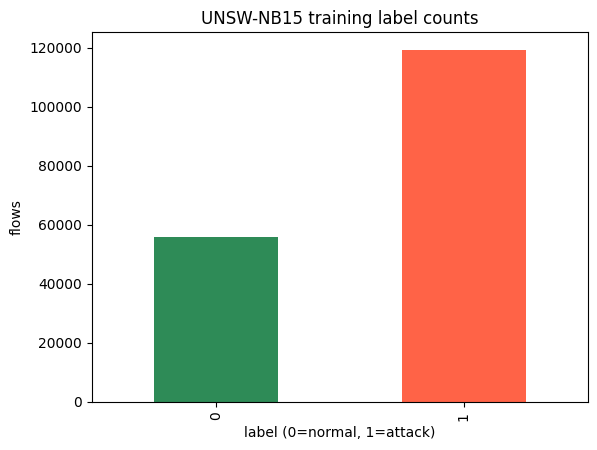

In [3]:
display(train_df.head())
display(train_df.dtypes.value_counts().rename("column count").to_frame())
display(train_df.isna().sum().sort_values(ascending=False).head(15).to_frame("missing values"))

print("Training labels (0=normal, 1=attack):")
display(train_df["label"].value_counts(dropna=False).sort_index().to_frame("rows"))
print("Training attack categories:")
display(train_df["attack_cat"].fillna("<missing>").value_counts().to_frame("rows"))

ax = train_df["label"].value_counts().sort_index().plot.bar(color=["seagreen", "tomato"])
ax.set(title="UNSW-NB15 training label counts", xlabel="label (0=normal, 1=attack)", ylabel="flows")
plt.show()


## 4. Choose features and preprocess

We remove `id` because it identifies a row, and remove `label` and `attack_cat` because those are answers, not input features. Numeric columns are standardized; categorical protocol/service/state values are one-hot encoded. The preprocessor is fit only on benign training examples, preventing information from the test set from leaking into preprocessing. Unknown categories in the test set are safely ignored.

In [4]:
TARGET_COLUMNS = ["label", "attack_cat", "id"]
feature_columns = [c for c in train_df.columns if c not in TARGET_COLUMNS]

normal_train = train_df.loc[train_df["label"] == 0].copy()
if len(normal_train) < 100:
    raise ValueError("Too few benign rows in training data; verify the dataset and label convention.")

X_fit, X_val_raw = train_test_split(
    normal_train[feature_columns], test_size=0.2, random_state=SEED
)
X_train_raw = X_fit
X_test_raw = test_df[feature_columns]
y_test = test_df["label"].astype(int).to_numpy()

numeric_columns = X_fit.select_dtypes(include=[np.number]).columns.tolist()
categorical_columns = [c for c in feature_columns if c not in numeric_columns]
print("Benign training rows:", len(X_train_raw))
print("Numeric features:", len(numeric_columns), numeric_columns)
print("Categorical features:", len(categorical_columns), categorical_columns)

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_columns),
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.float32), categorical_columns),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)

X_train = preprocessor.fit_transform(X_train_raw).astype(np.float32)
X_val = preprocessor.transform(X_val_raw).astype(np.float32)
X_test = preprocessor.transform(X_test_raw).astype(np.float32)

print("Encoded shapes:", X_train.shape, X_val.shape, X_test.shape)
print("All finite:", np.isfinite(X_train).all(), np.isfinite(X_val).all(), np.isfinite(X_test).all())


Benign training rows: 44800
Numeric features: 39 ['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports']
Categorical features: 3 ['proto', 'service', 'state']
Encoded shapes: (44800, 64) (11200, 64) (82332, 64)
All finite: True True True


## 5. Build the autoencoder

An autoencoder maps input features into a smaller latent representation, then reconstructs the original vector. If trained only on benign flows, it should usually reconstruct similar benign patterns better than unfamiliar patterns. We use mean squared reconstruction error as the anomaly score.

In [5]:
input_dim = X_train.shape[1]
inputs = tf.keras.Input(shape=(input_dim,), name="network_flow_features")
x = tf.keras.layers.Dense(128, activation="relu")(inputs)
x = tf.keras.layers.Dense(64, activation="relu")(x)
latent = tf.keras.layers.Dense(16, activation="relu", name="latent_space")(x)
x = tf.keras.layers.Dense(64, activation="relu")(latent)
x = tf.keras.layers.Dense(128, activation="relu")(x)
outputs = tf.keras.layers.Dense(input_dim, activation="linear", name="reconstructed_features")(x)

autoencoder = tf.keras.Model(inputs, outputs, name="netsentinel_autoencoder")
autoencoder.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3), loss="mse")
autoencoder.summary()


Model: "netsentinel_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ network_flow_features           │ (None, 64)             │             0 │
│ (InputLayer)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_space (Dense)            │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reconstructed_features (Dense)  │ (None, 64)             │         8,256 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 35,280 (137.81 KB)

 Trainable params: 35,280 (137.81 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Train on benign flows

The validation set also contains only benign training rows. Early stopping keeps the best validation-loss weights and helps prevent the model from simply memorizing the training examples.

Epoch 1/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 6s 36ms/step - loss: 0.3164 - val_loss: 0.1107
Epoch 2/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0758 - val_loss: 0.0515
Epoch 3/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0427 - val_loss: 0.0338
Epoch 4/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0290 - val_loss: 0.0245
Epoch 5/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0218 - val_loss: 0.0196
Epoch 6/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0176 - val_loss: 0.0161
Epoch 7/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0145 - val_loss: 0.0134
Epoch 8/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0122 - val_loss: 0.0116
Epoch 9/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0107 - val_loss: 0.0102
Epoch 10/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0095 - val_loss: 0.0092
Epoch 11/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0086 - val_loss: 0.0085
Epoch 12/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0079 - val_l

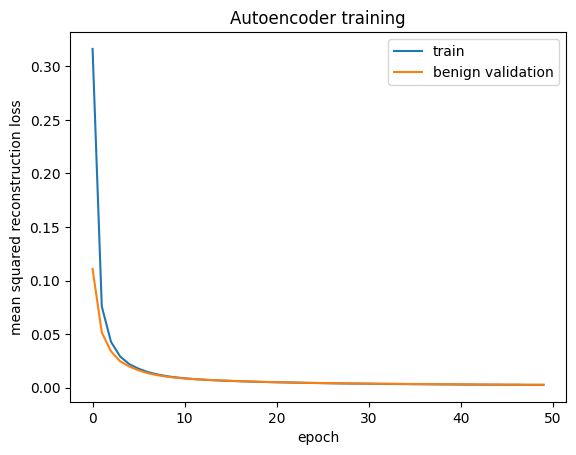

In [6]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True
)

history = autoencoder.fit(
    X_train, X_train,
    validation_data=(X_val, X_val),
    epochs=50,
    batch_size=512,
    shuffle=True,
    callbacks=[early_stop],
    verbose=1,
)

plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="benign validation")
plt.xlabel("epoch")
plt.ylabel("mean squared reconstruction loss")
plt.title("Autoencoder training")
plt.legend()
plt.show()


## 7. Set an anomaly threshold

We calculate reconstruction error for benign validation examples and set the threshold to their 95th percentile. This means roughly 5% of the benign validation examples may exceed the threshold by construction. The percentile is a project choice; later, compare 90%, 95%, and 99% to discuss the precision/recall tradeoff.

In [7]:
def reconstruction_error(model, features, batch_size=2048):
    reconstructed = model.predict(features, batch_size=batch_size, verbose=0)
    return np.mean(np.square(features - reconstructed), axis=1)

val_scores = reconstruction_error(autoencoder, X_val)
threshold = float(np.percentile(val_scores, 95))
print(f"95th-percentile benign validation threshold: {threshold:.6f}")
print("Validation errors:", pd.Series(val_scores).describe().round(6).to_dict())


95th-percentile benign validation threshold: 0.008799
Validation errors: {'count': 11200.0, 'mean': 0.002581, 'std': 0.023403, 'min': 7.7e-05, '25%': 0.000356, '50%': 0.000677, '75%': 0.001595, 'max': 2.29968}


## 8. Detect and evaluate anomalies

The test labels are used only now for evaluation, not for fitting the preprocessor, model, or threshold. Results measure how well this simple unsupervised approach separates the provided benign and attack records. Because the benchmark contains known attack types, this is not a guarantee of performance on live traffic or truly unseen attacks.

Test label counts:


,rows
normal,37000
attack,45332



Classification report (0=normal, 1=attack):
              precision    recall  f1-score   support

      normal     0.7953    0.8999    0.8444     37000
      attack     0.9085    0.8110    0.8570     45332

    accuracy                         0.8509     82332
   macro avg     0.8519    0.8554    0.8507     82332
weighted avg     0.8576    0.8509    0.8513     82332

Accuracy: 0.8509
F1: 0.857
ROC-AUC (score-based): 0.92
PR-AUC / average precision: 0.9301


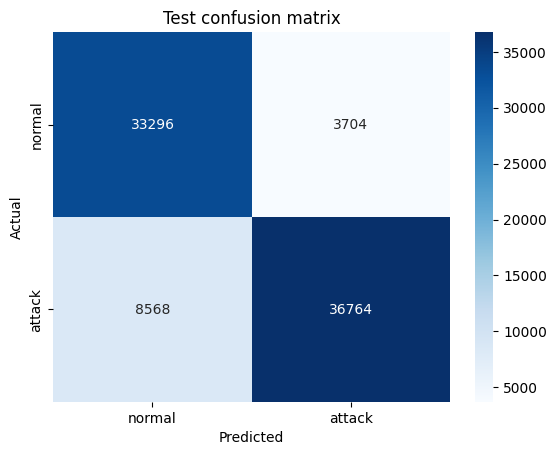

In [8]:
test_scores = reconstruction_error(autoencoder, X_test)
y_pred = (test_scores > threshold).astype(int)

print("Test label counts:")
display(pd.Series(y_test).value_counts().sort_index().rename(index={0: "normal", 1: "attack"}).to_frame("rows"))
print("\nClassification report (0=normal, 1=attack):")
print(classification_report(y_test, y_pred, target_names=["normal", "attack"], digits=4, zero_division=0))
print("Accuracy:", round(np.mean(y_pred == y_test), 4))
print("F1:", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("ROC-AUC (score-based):", round(roc_auc_score(y_test, test_scores), 4))
print("PR-AUC / average precision:", round(average_precision_score(y_test, test_scores), 4))

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["normal", "attack"], yticklabels=["normal", "attack"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Test confusion matrix")
plt.show()


## 9. Visualize scores and threshold choices

A useful demo should show both the threshold and score distributions. Try changing the percentile below; do not choose it by looking at the test labels if you want a clean evaluation.

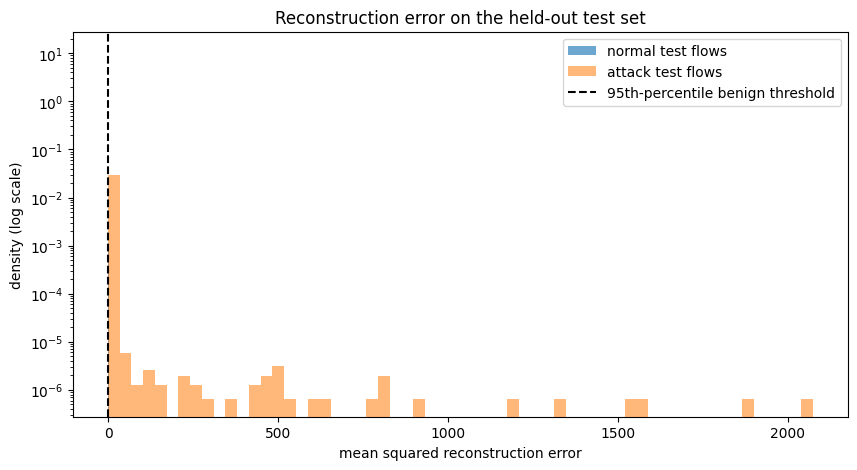

90th percentile | threshold=0.00422 | F1=0.8573
95th percentile | threshold=0.00880 | F1=0.8570
99th percentile | threshold=0.03087 | F1=0.7700


In [9]:
plt.figure(figsize=(10, 5))
plt.hist(test_scores[y_test == 0], bins=60, alpha=0.65, label="normal test flows", density=True)
plt.hist(test_scores[y_test == 1], bins=60, alpha=0.55, label="attack test flows", density=True)
plt.axvline(threshold, color="black", linestyle="--", label="95th-percentile benign threshold")
plt.yscale("log")
plt.xlabel("mean squared reconstruction error")
plt.ylabel("density (log scale)")
plt.title("Reconstruction error on the held-out test set")
plt.legend()
plt.show()

for percentile in [90, 95, 99]:
    candidate_threshold = np.percentile(val_scores, percentile)
    candidate_pred = (test_scores > candidate_threshold).astype(int)
    print(f"{percentile:>2}th percentile | threshold={candidate_threshold:.5f} | F1={f1_score(y_test, candidate_pred, zero_division=0):.4f}")


## 10. Save a lightweight model artifact (optional)

This saves the neural network and preprocessing object in the temporary Colab runtime. Download only these small artifacts if you want to keep them. The dataset itself need not be copied to your computer.

In [10]:
autoencoder.save("/content/netsentinel_autoencoder.keras")
print("Saved model to /content/netsentinel_autoencoder.keras")
# To download it to your computer, uncomment:
# from google.colab import files
# files.download("/content/netsentinel_autoencoder.keras")


Saved model to /content/netsentinel_autoencoder.keras


## What to explain in your PBL presentation

- **Problem:** labeled rules can miss unusual traffic patterns; this model learns a baseline from benign network-flow features.
- **Deep learning idea:** the encoder compresses features into a latent vector and the decoder reconstructs them.
- **Anomaly score:** mean squared difference between original and reconstructed features.
- **Threshold:** the 95th percentile of benign validation errors; the chosen percentile changes false alarms and missed attacks.
- **Evaluation:** report precision, recall, F1, confusion matrix, ROC-AUC, and PR-AUC. Explain why PR-AUC is useful with class imbalance.
- **Limitation:** high reconstruction error means unusual relative to this training data, not necessarily malicious. This is an offline benchmark, not a production intrusion detector.

**Dataset source and citation:** UNSW-NB15 is maintained by UNSW Canberra. See the [official dataset page](https://research.unsw.edu.au/projects/unsw-nb15-dataset) for dataset details and required academic citations. This notebook downloads the two split CSVs from a public GitHub mirror; compare file columns/counts against the official descriptions if your results need to be fully reproducible.

**Next milestone:** run through Section 3 and share the shapes, label counts, and any errors. Then we can verify the dataset and preprocessing choices together before you interpret model results.


In [11]:
import joblib

joblib.dump(
    {"preprocessor": preprocessor, "threshold": float(threshold)},
    "/content/netsentinel_preprocessing.joblib"
)

['/content/netsentinel_preprocessing.joblib']

In [12]:
import joblib
import numpy as np
import tensorflow as tf
import pandas as pd

model = tf.keras.models.load_model("/content/netsentinel_autoencoder.keras")
bundle = joblib.load("/content/netsentinel_preprocessing.joblib")

preprocessor = bundle["preprocessor"]
threshold = bundle["threshold"]

# Pick three normal and three attack examples for a quick demo.
sample = pd.concat([
    test_df[test_df["label"] == 0].head(3),
    test_df[test_df["label"] == 1].head(3)
], ignore_index=True)

# Labels identify examples for checking; they aren't model inputs.
excluded = ["id", "label", "attack_cat"]
feature_columns = [c for c in train_df.columns if c not in excluded]
X_sample = preprocessor.transform(sample[feature_columns]).astype(np.float32)

reconstructed = model.predict(X_sample, verbose=0)
scores = np.mean(np.square(X_sample - reconstructed), axis=1)

display(pd.DataFrame({
    "dataset label (check only)": sample["label"].map({0: "normal", 1: "attack"}),
    "NetSentinel result": np.where(scores > threshold, "flag for review", "looks normal"),
    "anomaly score": scores.round(5),
    "threshold": round(threshold, 5)
}))

,dataset label (check only),NetSentinel result,anomaly score,threshold
0,normal,looks normal,0.00161,0.0088
1,normal,looks normal,0.00111,0.0088
2,normal,looks normal,0.00157,0.0088
3,attack,flag for review,0.08171,0.0088
4,attack,flag for review,0.08171,0.0088
5,attack,flag for review,0.08171,0.0088


In [13]:
from google.colab import output
output.enable_custom_widget_manager()

import ipywidgets as widgets
from IPython.display import display, HTML

# Use a balanced set of examples for the demonstration.
demo_rows = pd.concat([
    test_df[test_df["label"] == 0].head(10),
    test_df[test_df["label"] == 1].head(10)
], ignore_index=True).sample(frac=1, random_state=7).reset_index(drop=True)

excluded = ["id", "label", "attack_cat"]
feature_columns = [c for c in train_df.columns if c not in excluded]

def show_flow(example_number):
    row = demo_rows.iloc[[example_number]]

    # Labels are shown only for comparison; the model doesn't receive them.
    flow_features = row[feature_columns]
    encoded = preprocessor.transform(flow_features).astype(np.float32)
    reconstructed = model.predict(encoded, verbose=0)
    score = float(np.mean(np.square(encoded - reconstructed)))

    flagged = score > threshold
    result = "FLAG FOR REVIEW" if flagged else "Looks normal"
    color = "#c62828" if flagged else "#2e7d32"
    reference_label = "attack" if int(row["label"].iloc[0]) == 1 else "normal"

    display(HTML(
        f"<h3 style='color:{color}'>{result}</h3>"
        f"<p>Anomaly score: <b>{score:.5f}</b> &nbsp;|&nbsp; "
        f"Threshold: <b>{threshold:.5f}</b></p>"
        f"<p>Dataset label for comparison: <b>{reference_label}</b></p>"
    ))

    flow_columns = ["proto", "service", "state", "dur", "spkts", "dpkts", "sbytes", "dbytes"]
    display(row[flow_columns].T.rename(columns={row.index[0]: "Flow details"}))

selector = widgets.IntSlider(
    value=0,
    min=0,
    max=len(demo_rows) - 1,
    step=1,
    description="Example",
    continuous_update=False
)

display(widgets.VBox([
    widgets.HTML("<b>Move the slider to inspect a different network flow.</b>"),
    selector,
    widgets.interactive_output(show_flow, {"example_number": selector})
]))